# 10 · Operator commands: the data and the classical baselines

**Phase 6 · NLP + Transformers.** Operators should control the warehouse in plain words:
*"send R-36 around aisle 2 now"*, *"pause robot 7"*, *"how many units of P-C-29-03 are left?"*.
Understanding a message takes three steps:

| Step | Example | Done by |
|---|---|---|
| 1. **Intent**: what does the operator want? | `reroute_robot` | a classifier (this notebook: rules, TF-IDF; notebook 11: a Transformer) |
| 2. **Entities**: which words name what? | ROBOT "R-36" · AISLE "aisle 2" | a tagger (here: regular expressions) |
| 3. **Tool call**: the exact backend action | `reroute_robot(robot_id="R36", avoid=["AISLE_02"])` | fixed rules (`ai/nlp/commands.py`) |

Write actions (pause, reroute, close an aisle, create an order...) always need the operator's
**approval** in the app; read-only questions are answered at once.

**How we score.** Intent accuracy and macro F1; entity F1 on (type, canonical value) pairs; and the
strictest number, the **exact tool call**: the share of messages whose complete backend call is
right, i.e. what the app would really execute.

In [1]:
import sys
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from ai.nlp.commands import (  # noqa: E402
    INTENTS,
    bio,
    honest_validation,
    load_commands,
    normalize,
    requires_approval,
    same_calls,
    spans_from_bio,
    tool_calls,
)  # fmt: skip
from ai.nlp.evaluation import evaluate, noisy, summary  # noqa: E402
from ai.nlp.intent_parser import RuleParser, TfidfParser  # noqa: E402

MODELS = ROOT / "models"
pd.set_option("display.max_colwidth", 90)
df = load_commands()
print(f"{len(df):,} messages, {df['intent'].nunique()} intents, {df['template_id'].nunique()} phrasing templates")

5,461 messages, 17 intents, 156 phrasing templates


## 1. The data

In [2]:
counts = df.pivot_table(index="intent", columns="split", values="id", aggfunc="count").fillna(0).astype(int)
counts["needs approval"] = df.groupby("intent")["requires_approval"].first().map({True: "yes", False: "no"})
counts.sort_values("train", ascending=False)

split,test,train,validation,needs approval
intent,,,,
robot_status,80,358,42,no
inventory_query,80,287,32,no
close_aisle,80,260,20,yes
assign_order,80,256,24,yes
pause_robot,79,255,25,yes
reroute_robot,80,252,28,yes
knowledge_query,72,250,13,no
open_aisle,40,220,20,yes
investigate_delay,80,216,23,no


In [3]:
examples = df[df["split"] == "test"].groupby("intent").head(1)[["intent", "text", "tool_calls"]]
examples.assign(tool_calls=examples["tool_calls"].map(lambda c: "; ".join(
    f"{x['name']}({', '.join(f'{k}={v}' for k, v in x['arguments'].items())})" for x in c) or "none"))

,intent,text,tool_calls
4,pause_robot,"copilot, R-12 needs to stop now",pause_robot(robot_id=R12)
5,route_planning,"copilot, Show the path r7 would take to A-08-11","calculate_route(robot_id=R7, destination=A-08-11)"
6,open_aisle,reopen AISLE_01,open_aisle(aisle_id=AISLE_01)
8,task_assignment,All MEDIUM orders should go to packing 6,get_pending_orders(priority=MEDIUM)
9,create_order,create a low-priority order for 3 units of p-c-29-03 now,"create_order(priority=LOW, items=[{'product_id': 'P-C-29-03', 'quantity': 3}])"
13,assign_order,assign o00864 to Robot 36?,"assign_order(robot_id=R36, order_id=O00864)"
21,resume_robot,quick one: Unpause AMR 34,resume_robot(robot_id=R34)
22,pending_orders,which orders are waiting for a robot.,get_pending_orders()
27,knowledge_query,please what should happen when a robot's battery is critiacl,search_knowledge(query=what should happen when a robot's battery is critical)
55,robot_status,please What task is robot 2 on,get_robot_status(robot_id=R2)


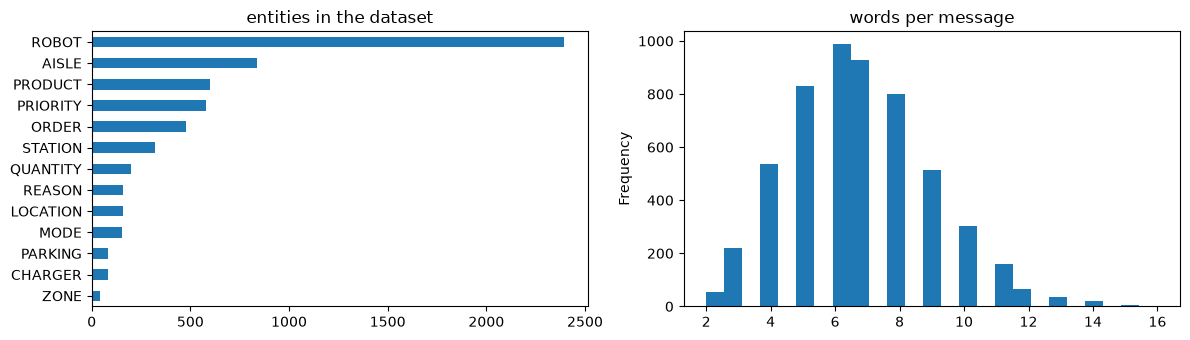

median 7 words; 19% of messages have no entity; 46% need approval


In [4]:
ent = Counter(e["type"] for es in df["entities"] for e in es)
words = df["text"].str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
pd.Series(ent).sort_values().plot.barh(ax=ax[0], title="entities in the dataset")
words.plot.hist(bins=25, ax=ax[1], title="words per message")
plt.tight_layout()
plt.show()
print(f"median {words.median():.0f} words; {(df['entities'].str.len() == 0).mean():.0%} of messages have no entity; "
      f"{df['requires_approval'].mean():.0%} need approval")

**Realistic noise:** robots are written "R-12", "AMR 20", "bot 3", "robot #5"; products in
lower case; filler ("quick one:", "please", "asap"); about one message in eight has a typo
("critiacl", "by ahnd").

In [5]:
surface = pd.DataFrame([(e["type"], e["text"], e["value"]) for es in df["entities"] for e in es],
                       columns=["type", "words", "canonical value"])
surface[surface["type"].isin(["ROBOT", "AISLE", "PRIORITY"])].drop_duplicates("words").groupby("type").head(6)

,type,words,canonical value
0,ROBOT,robot R36,R36
1,AISLE,Aisle 2,AISLE_02
2,ROBOT,robot 12,R12
3,ROBOT,R-12,R12
5,ROBOT,r7,R7
7,AISLE,AISLE_01,AISLE_01
8,PRIORITY,MEDIUM,MEDIUM
10,PRIORITY,low-priority,LOW
13,PRIORITY,high,HIGH
16,AISLE,aisle 35,AISLE_35


## 2. The shared rules reproduce every label

Step 3 is not learned: `normalize` turns an entity's words into its canonical value and
`tool_calls` builds the backend call. The dataset generator uses the same functions, so the rules
must reproduce **every** label exactly.

In [6]:
norm = sum(normalize(e["type"], e["text"]) != e["value"] for es in df["entities"] for e in es)
calls = sum(not same_calls(tool_calls(r.intent, r.entities, r.text), r.tool_calls) for r in df.itertuples())
tags = sum(bio(r.text, r.entities) != (r.tokens, r.bio_tags) for r in df.itertuples())
spans = sum([(s["type"], s["start"], s["end"]) for s in spans_from_bio(r.text, r.bio_tags)]
            != [(e["type"], e["start"], e["end"]) for e in r.entities] for r in df.itertuples())
approval = sum(requires_approval(r.tool_calls) != r.requires_approval for r in df.itertuples())
print(f"mismatches over {len(df):,} messages: values {norm}, tool calls {calls}, BIO tags {tags}, spans {spans}, approval {approval}")

mismatches over 5,461 messages: values 0, tool calls 0, BIO tags 0, spans 0, approval 0


## 3. An honest validation split

The **test** split holds out whole phrasing templates (32 templates that never occur in training):
it measures understanding of *new wordings*. The dataset's own validation rows, however, share
templates with training, so model choices made on them would reward memorised sentences. We
therefore build a validation split that also holds out whole training templates.

In [7]:
df["split2"] = honest_validation(df)
train, val, test = (df[df["split2"] == s] for s in ("train", "validation", "test"))
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:10s} {len(part):5,} messages, {part['template_id'].nunique():3d} templates")
print("validation templates also in train:", len(set(val["template_id"]) & set(train["template_id"])))
print("test templates also in train:      ", len(set(test["template_id"]) & set(train["template_id"])))

train      3,535 messages, 101 templates
validation   796 messages,  23 templates
test       1,130 messages,  32 templates
validation templates also in train: 0
test templates also in train:       0


## 4. Baselines

* **Rules:** the first matching keyword pattern decides the intent ("stop", "halt" → pause);
  regular expressions find the entities.
* **TF-IDF + Logistic Regression:** the message becomes a weighted bag of words (1-2 words) and
  character fragments (2-5 characters, which tolerate typos); a logistic regression picks the
  intent. Entities: the same regular expressions.

In [8]:
rules = RuleParser()
tfidf = TfidfParser().fit(list(train["text"]), list(train["intent"]))
scores = {}
for parser in (rules, tfidf):
    scores[(parser.name, "validation")] = evaluate(parser.parse, val)
    scores[(parser.name, "test")] = evaluate(parser.parse, test)
    scores[(parser.name, "test + noise")] = evaluate(parser.parse, test, noisy(test))
table = pd.DataFrame({k: summary(v) for k, v in scores.items()}).T
table.round(3)

intent_accuracy  \
Rules (keywords + regex)                        validation              0.477   
                                                test                    0.657   
                                                test + noise            0.540   
TF-IDF + Logistic Regression (+ regex entities) validation              0.496   
                                                test                    0.695   
                                                test + noise            0.666   

                                                              intent_macro_F1  \
Rules (keywords + regex)                        validation              0.376   
                                                test                    0.691   
                                                test + noise            0.590   
TF-IDF + Logistic Regression (+ regex entities) validation              0.477   
                                                test                    0.670   
                                                test + noise            0.645   

                                                              entity_precision  \
Rules (keywords + regex)                        validation               0.949   
                                                test                     1.000   
                                                test + noise             1.000   
TF-IDF + Logistic Regression (+ regex entities) validation               0.949   
                                                test                     1.000   
                                                test + noise             1.000   

                                                              entity_recall  \
Rules (keywords + regex)                        validation            0.938   
                                                test                  0.999   
                                                test + noise          0.988   
TF-IDF + Logistic Regression (+ regex entities) validation            0.938   
                                                test                  0.999   
                                                test + noise          0.988   

                                                              entity_F1  \
Rules (keywords + regex)                        validation        0.943   
                                                test              1.000   
                                                test + noise      0.994   
TF-IDF + Logistic Regression (+ regex entities) validation        0.943   
                                                test              1.000   
                                                test + noise      0.994   

                                                              exact_tool_call  \
Rules (keywords + regex)                        validation              0.480   
                                                test                    0.656   
                                                test + noise            0.526   
TF-IDF + Logistic Regression (+ regex entities) validation              0.486   
                                                test                    0.725   
                                                test + noise            0.679   

                                                              approval_correct  \
Rules (keywords + regex)                        validation               0.653   
                                                test                     0.823   
                                                test + noise             0.742   
TF-IDF + Logistic Regression (+ regex entities) validation               0.784   
                                                test                     0.933   
                                                test + noise             0.929   

                                                              ms_per_message  
Rules (keywords + regex)                        v

**Reading the table.** Entities are easy for patterns here (F1 ≈ 1.0): the dataset's IDs use a
handful of formats. The hard part is the **intent of new phrasings**: about 7 in 10 test messages
are understood, and fewer on the honest validation split. Word-counting methods do not know that
"R-12 needs to stop now" means *pause* when training only said "pause robot 12".

## 5. Where TF-IDF fails (test)

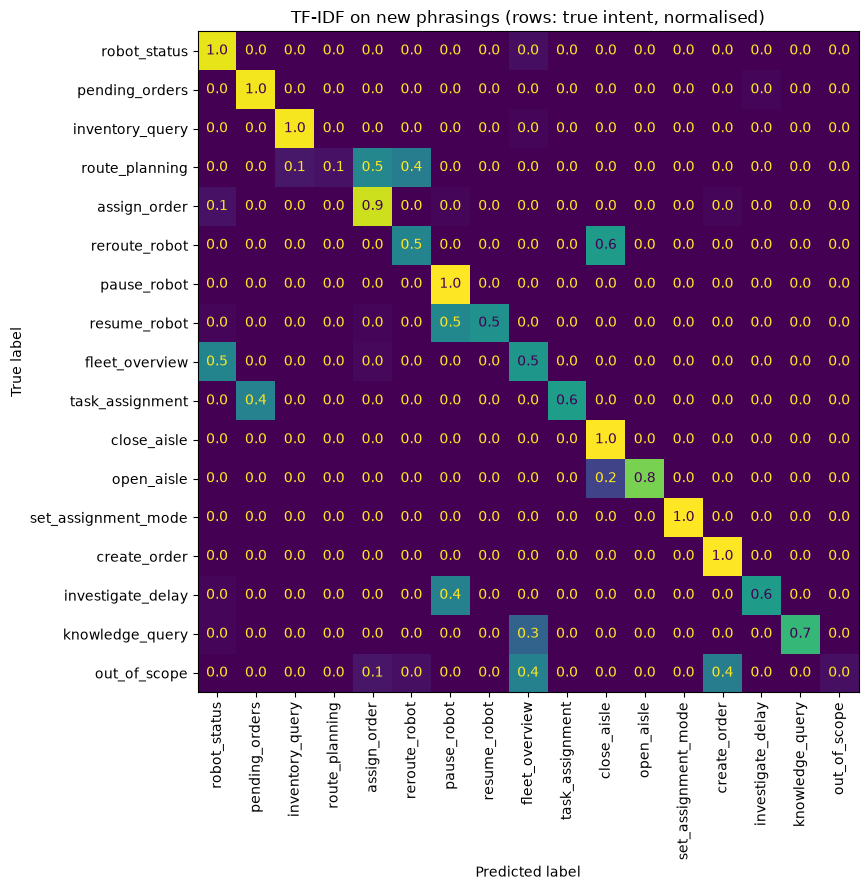

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

pred = scores[(tfidf.name, "test")]["predictions"]
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(test["intent"], pred, labels=INTENTS, ax=ax, xticks_rotation=90,
                                        colorbar=False, normalize="true", values_format=".1f")
ax.set_title("TF-IDF on new phrasings (rows: true intent, normalised)")
plt.tight_layout()
plt.show()

In [10]:
wrong = test.assign(predicted=pred)[lambda d: d["predicted"] != d["intent"]]
print(f"{len(wrong)} of {len(test)} test messages get the wrong intent; most common confusions:")
display(wrong.groupby(["intent", "predicted"]).size().sort_values(ascending=False).head(8).rename("messages").to_frame())
wrong.groupby(["intent", "predicted"]).head(1).head(8)[["text", "intent", "predicted"]]

345 of 1130 test messages get the wrong intent; most common confusions:


,,messages
intent,predicted,
reroute_robot,close_aisle,44
resume_robot,pause_robot,37
route_planning,assign_order,37
task_assignment,pending_orders,35
investigate_delay,pause_robot,35
route_planning,reroute_robot,34
knowledge_query,fleet_overview,23
fleet_overview,robot_status,23


,text,intent,predicted
5,"copilot, Show the path r7 would take to A-08-11",route_planning,assign_order
21,quick one: Unpause AMR 34,resume_robot,pause_robot
35,please handle the LOW orders first,task_assignment,pending_orders
114,"hey copilot, Robot 7 must avoid aisle 17 now",reroute_robot,close_aisle
156,please How often are cameras calibrated,knowledge_query,fleet_overview
230,reopen Aisle 50 thanks,open_aisle,close_aisle
264,"hey copilot, why did R8 stop asap",investigate_delay,pause_robot
275,quick one: order me a pizza?,out_of_scope,create_order


In [11]:
per_intent = pd.DataFrame(classification_report(test["intent"], pred, output_dict=True, zero_division=0)).T
per_intent.loc[INTENTS, ["precision", "recall", "f1-score", "support"]].round(2).sort_values("f1-score")

,precision,recall,f1-score,support
out_of_scope,1.00,0.04,0.08,50.0
route_planning,1.00,0.05,0.10,80.0
fleet_overview,0.36,0.53,0.43,51.0
reroute_robot,0.50,0.45,0.47,80.0
resume_robot,1.00,0.51,0.67,79.0
pause_robot,0.52,1.00,0.68,79.0
investigate_delay,0.98,0.55,0.70,80.0
task_assignment,1.00,0.56,0.72,79.0
close_aisle,0.61,1.00,0.75,80.0
assign_order,0.64,0.92,0.76,80.0


## 6. Save the TF-IDF baseline (the app's fallback parser) and the scores

In [12]:
import json

joblib.dump({"model": tfidf.model, "algorithm": tfidf.name}, MODELS / "nlp_tfidf_v1.joblib")
report = {
    "model": "nlp_tfidf_v1",
    "split": {"train": len(train), "validation": len(val), "test": len(test)},
    "scores": {f"{name} | {part}": summary(s) for (name, part), s in scores.items()},
}
(MODELS / "nlp_baselines_report.json").write_text(json.dumps(report, indent=2))
print("Saved models/nlp_tfidf_v1.joblib and models/nlp_baselines_report.json")

Saved models/nlp_tfidf_v1.joblib and models/nlp_baselines_report.json
